# LAB 04 — Decision Tree: từ dự đoán đến quy tắc hỗ trợ

**DNU Learning Analytics Lab**

- **Họ tên:** Lê Trung Kiên
- **MSSV:** 1771020404
- **Lớp:** CNTT 18-02

> **Câu hỏi trung tâm:** Decision Tree đưa ra dự đoán bằng những câu hỏi nào, và làm thế nào để biến một cây quyết định thành các quy tắc có thể giải thích?

Lab 04 dùng **cùng bài toán, cùng feature, cùng target và cùng train/test split của Lab 02–03**.

- K-NN: “Bạn giống ai?”
- Naive Bayes: “Khả năng thuộc lớp nào?”
- Decision Tree: **“Những quyết định nào dẫn đến kết quả?”**

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("data/StudentPerformanceFactors.csv")
print("Environment ready! Dataset exists:", DATA_PATH.exists())

Environment ready! Dataset exists: True


# Mission 1 — Back to DNU case study

Ta giữ nguyên bài toán của Lab 02–03:

```text
Needs_Support = 1 nếu Exam_Score < 65
```

Feature chính:

```text
Hours_Studied
Attendance
Previous_Scores
Sleep_Hours
```

**Quan trọng:** Không dùng `Exam_Score` làm feature vì target được tạo trực tiếp từ biến này.

[TRẢ LỜI]

1. **Vì sao dùng Exam_Score làm feature sẽ gây target leakage?**
   - Biến mục tiêu `Needs_Support` được tạo ra trực tiếp bằng quy tắc logic toán học `Exam_Score < 65`. 
   - Nếu đưa `Exam_Score` vào làm đặc trưng (feature) đầu vào, mô hình sẽ "thấy trước đáp án" vì chỉ cần kiểm tra xem `Exam_Score` có nhỏ hơn 65 hay không. 
   - Điều này dẫn đến kết quả đánh giá giả tạo (Accuracy đạt 100%), nhưng mô hình sẽ hoàn toàn vô dụng trên thực tế khi cần dự đoán sớm nguy cơ học tập của sinh viên trước khi thi.

2. **Vì sao Lab 04 phải giữ cùng train/test split với Lab 02–03?**
   - **Đảm bảo tính so sánh công bằng (Fair Comparison):** Giữ nguyên tập huấn luyện (train) và tập kiểm tra (test) chính xác tới từng mẫu dữ liệu giúp đảm bảo mọi sự thay đổi về độ chính xác hay hiệu năng (Accuracy, Precision, Recall, F1) giữa các mô hình (K-NN ở Lab 02, Naive Bayes ở Lab 03, Decision Tree ở Lab 04) đều xuất phát từ bản chất của **thuật toán** chứ không phải do sự may mắn hay thay đổi của phân bố dữ liệu.
   - **Đảm bảo tính nhất quán thực nghiệm:** Giúp dễ dàng theo dõi và so sánh sự khác biệt trong ranh giới quyết định (Decision Boundary) của các mô hình trên cùng một tập bài toán DNU Learning Analytics.

In [14]:
if not DATA_PATH.exists():
    raise FileNotFoundError("Run: python scripts/download_data.py")

df = pd.read_csv(DATA_PATH).copy()
df["Needs_Support"] = (df["Exam_Score"] < 65).astype(int)

feature_cols = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
]

assert "Exam_Score" not in feature_cols

model_df = df[feature_cols + ["Needs_Support"]].dropna().copy()
X = model_df[feature_cols]
y = model_df["Needs_Support"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
display(y_train.value_counts().rename("count").to_frame())
display(y_train.value_counts(normalize=True).rename("ratio").to_frame())

Train: (4955, 4) Test: (1652, 4)


,count
Needs_Support,
0,3866
1,1089


,ratio
Needs_Support,
0,0.780222
1,0.219778


# Mission 2 — Baseline Decision Tree

Huấn luyện cây đầu tiên với thiết lập mặc định.

> Ở bước này **không scale dữ liệu**. Decision Tree chia dữ liệu theo ngưỡng của từng feature, nên scaling không phải bước bắt buộc như K-NN.

[TRẢ LỜI]

* **Baseline tree có độ sâu bao nhiêu?**
  - Mô hình baseline Decision Tree có độ sâu là **21**.

* **Có bao nhiêu node và leaf?**
  - Tổng số nút (`Number of nodes`): **1489** nút.
  - Số lượng nút lá (`Number of leaves`): **745** lá.

* **Theo bạn, một cây rất sâu có dễ giải thích không?**
  - **Không dễ giải thích.** Một cây quá sâu (độ sâu 21) với hàng trăm nhánh và nút lá sẽ tạo ra một tập hợp luật IF-THEN cực kỳ phức tạp và chồng chéo. Điều này làm mất đi ưu điểm lớn nhất của Decision Tree là tính trực quan, dễ diễn giải (White-box model), đồng thời làm cho mô hình rất dễ gặp hiện tượng **Overfitting** (học vẹt trên tập train).

In [15]:
tree_baseline = DecisionTreeClassifier(random_state=42)
tree_baseline.fit(X_train, y_train)

print("Tree depth:", tree_baseline.get_depth())
print("Number of leaves:", tree_baseline.get_n_leaves())
print("Number of nodes:", tree_baseline.tree_.node_count)

Tree depth: 21
Number of leaves: 745
Number of nodes: 1489


# Mission 3 — Evaluate beyond Accuracy

Đánh giá bằng:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Đặc biệt chú ý:

> **False Negative (FN): sinh viên thực tế cần hỗ trợ nhưng mô hình dự đoán không cần hỗ trợ.**

[TRẢ LỜI]

1. **Nếu mục tiêu là hạn chế bỏ sót sinh viên cần hỗ trợ, metric nào cần được chú ý?**
   - Metric cần chú ý nhất là **Recall** (đặc biệt là Recall của lớp `Needs_Support = 1`).
   - **Lý do:** Recall đo lường tỷ lệ sinh viên thực sự cần hỗ trợ mà mô hình bắt được. Chỉ số Recall càng cao thì số lượng False Negative (sinh viên bị bỏ sót) càng nhỏ.

2. **Vì sao chỉ nhìn Accuracy là chưa đủ?**
   - **Hiện tượng mất cân bằng lớp (Class Imbalance):** Tập dữ liệu có số sinh viên không cần hỗ trợ (`No Support`) chiếm đa số. Một mô hình dù dự đoán rất tệ ở lớp cần hỗ trợ vẫn có thể đạt Accuracy tổng thể cao nhờ dự đoán đúng lớp đa số.
   - **Tầm quan trọng của hậu quả lỗi:** Accuracy coi mọi lỗi sai là như nhau. Tuy nhiên trong thực tế, lỗi **False Negative** (bỏ sót sinh viên gặp khó khăn) gây ra hậu quả nghiêm trọng hơn rất nhiều so với lỗi **False Positive** (dự đoán nhầm sinh viên khá thành cần hỗ trợ).

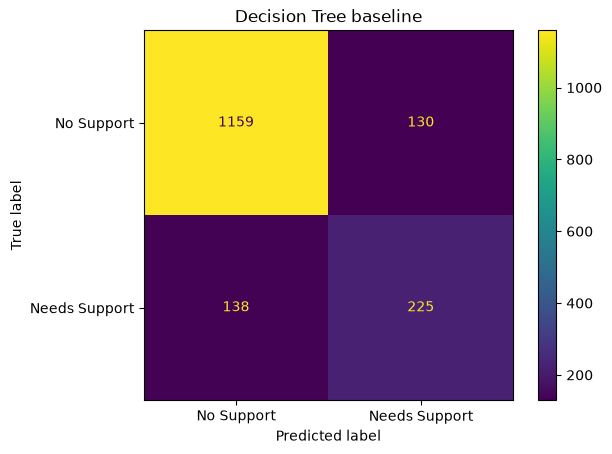

,model,accuracy,precision,recall,f1,tn,fp,fn,tp
0,Decision Tree baseline,0.837772,0.633803,0.619835,0.626741,1159,130,138,225


               precision    recall  f1-score   support

   No Support       0.89      0.90      0.90      1289
Needs Support       0.63      0.62      0.63       363

     accuracy                           0.84      1652
    macro avg       0.76      0.76      0.76      1652
 weighted avg       0.84      0.84      0.84      1652



In [16]:
def evaluate_binary(name, model, X_eval, y_eval, show_cm=True):
    pred = model.predict(X_eval)
    cm = confusion_matrix(y_eval, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    result = {
        "model": name,
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }

    if show_cm:
        ConfusionMatrixDisplay.from_predictions(
            y_eval, pred,
            display_labels=["No Support", "Needs Support"]
        )
        plt.title(name)
        plt.show()

    return result, pred

baseline_result, baseline_pred = evaluate_binary(
    "Decision Tree baseline",
    tree_baseline,
    X_test,
    y_test
)

display(pd.DataFrame([baseline_result]))
print(classification_report(
    y_test,
    baseline_pred,
    target_names=["No Support", "Needs Support"],
    zero_division=0
))

# Mission 4 — Read the Tree: từ cây sang quy tắc

Trong bài giảng, ta đã dùng ví dụ **Love AI** để tự xây cây bằng tay.

Bây giờ ta dùng cùng tư duy đó trên Student Performance Factors.

Để cây dễ đọc, tạo một **explainable tree** với `max_depth=3`.

### Nhiệm vụ

[TRẢ LỜI]

1. **Xác định Root Node:**
   - Root Node (Nút gốc) của cây là **`Attendance <= 70.500`**.

2. **Viết lại 2 đường Root → Leaf thành quy tắc bằng ngôn ngữ tự nhiên:**

   - **[TRẢ LỜI — RULE 1] (Nhánh dẫn đến lớp Cần hỗ trợ - class 1 / Needs Support):**
     - **Quy tắc:** `IF Attendance <= 70.50 AND Hours_Studied <= 21.50 AND Hours_Studied <= 15.50 THEN Needs_Support = 1 (Cần hỗ trợ)`
     - **Rút gọn:** `IF Attendance <= 70.50 AND Hours_Studied <= 15.50 THEN Needs_Support = 1`
     - **Diễn giải:** NẾU sinh viên có tỷ lệ đi học thấp ($\le 70.5\%$) VÀ thời gian tự học ít ($\le 15.5$ giờ) THÌ mô hình dự đoán sinh viên này **Cần hỗ trợ** (chiếm 6.4% dữ liệu với độ tin cậy $91.1\%$).

   - **[TRẢ LỜI — RULE 2] (Nhánh dẫn đến lớp Không cần hỗ trợ - class 0 / No Support):**
     - **Quy tắc:** `IF Attendance > 70.50 AND Hours_Studied > 14.50 AND Attendance > 78.50 THEN Needs_Support = 0 (Không cần hỗ trợ)`
     - **Diễn giải:** NẾU sinh viên có tỷ lệ đi học cao ($> 78.5\%$) VÀ thời gian tự học tốt ($> 14.5$ giờ) THÌ mô hình dự đoán sinh viên **Không cần hỗ trợ** (chiếm 43.4% dữ liệu với độ tin cậy $98.2\%$).

3. **Nhận xét: Cây ngắn hơn có đánh đổi điều gì so với baseline tree?**
   - **Sự đánh đổi (Trade-off):** Cây ngắn (`max_depth=3`) chấp nhận **đánh đổi một phần độ chính xác tuyệt đối (Accuracy/Recall)** trên tập huấn luyện so với cây gốc quá sâu (`max_depth=21`).
   - **Lợi ích thu lại:** Đổi lại, cây ngắn hơn mang lại **tính dễ giải thích (Explainability)** rất cao với các quy tắc đơn giản, trực quan, đồng thời **tránh hiện tượng Overfitting** và giúp mô hình tổng quát hóa tốt hơn trên tập kiểm tra (Test set).

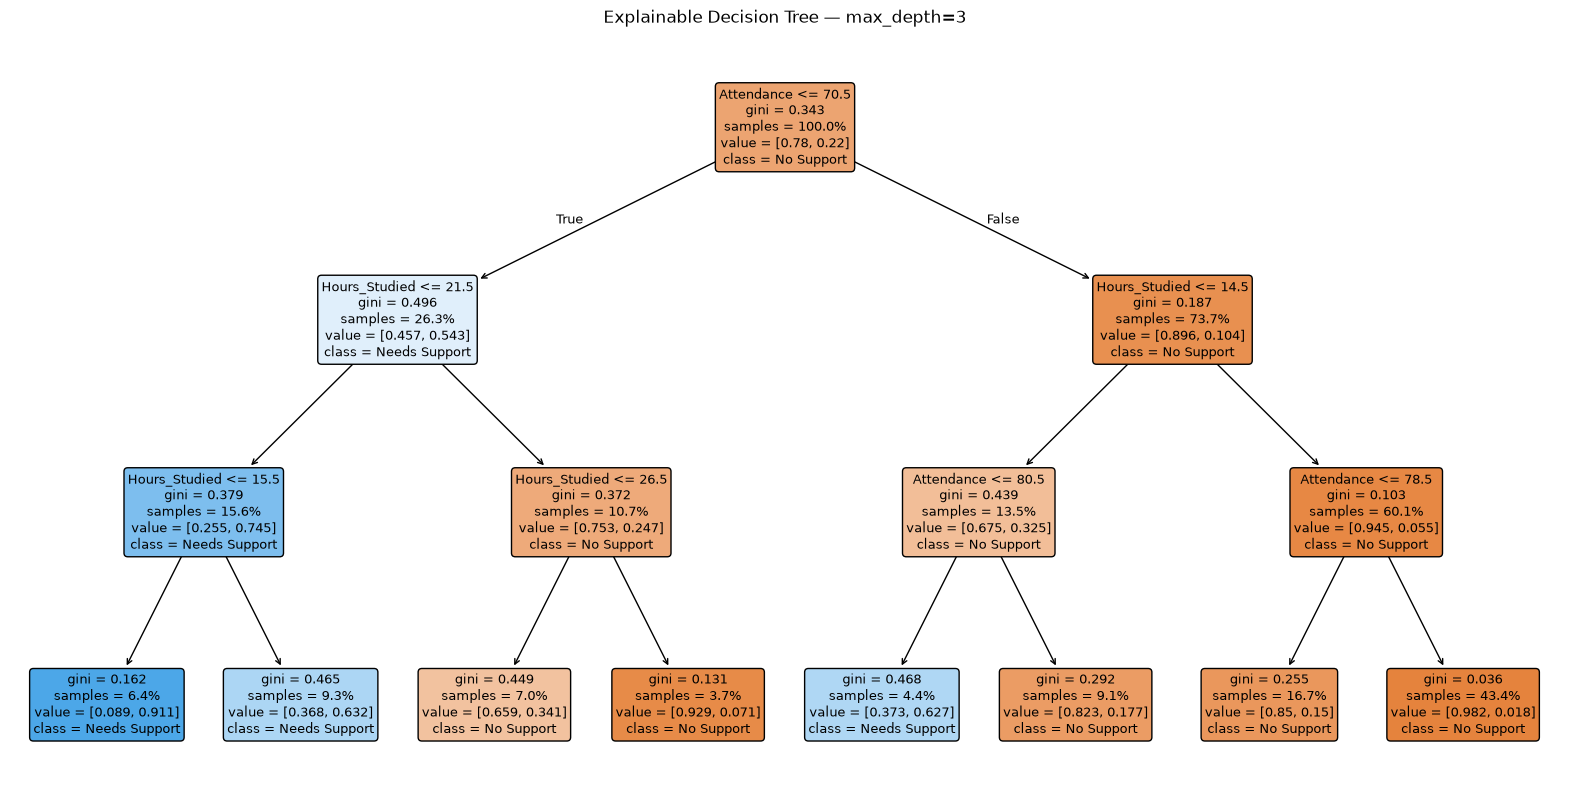

Text rules:
|--- Attendance <= 70.50
|   |--- Hours_Studied <= 21.50
|   |   |--- Hours_Studied <= 15.50
|   |   |   |--- class: 1
|   |   |--- Hours_Studied >  15.50
|   |   |   |--- class: 1
|   |--- Hours_Studied >  21.50
|   |   |--- Hours_Studied <= 26.50
|   |   |   |--- class: 0
|   |   |--- Hours_Studied >  26.50
|   |   |   |--- class: 0
|--- Attendance >  70.50
|   |--- Hours_Studied <= 14.50
|   |   |--- Attendance <= 80.50
|   |   |   |--- class: 1
|   |   |--- Attendance >  80.50
|   |   |   |--- class: 0
|   |--- Hours_Studied >  14.50
|   |   |--- Attendance <= 78.50
|   |   |   |--- class: 0
|   |   |--- Attendance >  78.50
|   |   |   |--- class: 0

Root node: Attendance <= 70.500


In [5]:
tree_explain = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
tree_explain.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(
    tree_explain,
    feature_names=feature_cols,
    class_names=["No Support", "Needs Support"],
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=9
)
plt.title("Explainable Decision Tree — max_depth=3")
plt.show()

print("Text rules:")
print(export_text(tree_explain, feature_names=feature_cols))

root_feature_index = tree_explain.tree_.feature[0]
root_feature = feature_cols[root_feature_index]
root_threshold = tree_explain.tree_.threshold[0]
print(f"Root node: {root_feature} <= {root_threshold:.3f}")

# Mission 5 — Complexity matters: cây sâu hơn có luôn tốt hơn?

Thử:

```python
max_depth = [2, 3, 5, None]
```

Ghi lại:

- Train Accuracy
- Test Accuracy
- Recall
- F1
- Số node
- Số leaf

[TRẢ LỜI]

1. **Khi cây sâu hơn, Train Accuracy thay đổi thế nào?**
   - `Train Accuracy` **tăng liên tục** theo độ sâu của cây, từ **85.69%** (khi `max_depth=2`) lên đỉnh điểm gần như tuyệt đối là **99.84%** (khi `max_depth=None` - độ sâu 21).

2. **Test Accuracy/F1 có tăng mãi không?**
   - **Không.** `Test Accuracy` và `Test F1-score` chỉ tăng trong khoảng từ `max_depth=2` đến `max_depth=5` (đạt cực đại tại `max_depth=5` với Test Accuracy = **87.05%** và Test F1 = **0.6787**). 
   - Sau đó, khi `max_depth=None`, cả Test Accuracy lẫn Test F1 đều **sụt giảm mạnh** (Test Accuracy giảm xuống còn **83.78%** và Test F1 giảm về **0.6267**).

3. **Dấu hiệu nào gợi ý overfitting?**
   - Dấu hiệu rõ nhất xuất hiện ở trường hợp **`max_depth=None`**:
     - **Khoảng cách (Gap) rất lớn giữa Train và Test:** `Train Accuracy` cực kỳ cao (**99.84%**), nhưng `Test Accuracy` lại giảm sâu xuống **83.78%** (chênh lệch tới hơn 16%).
     - Số lượng node tăng vọt lên **1489 nodes** (745 leaves), cho thấy mô hình đang cố "học vẹt" từng điểm dữ liệu nhiễu trong tập Train thay vì học quy luật tổng quát.

4. **Nếu phải trình bày mô hình cho cố vấn học tập, bạn sẽ ưu tiên cây nào và vì sao?**
   - **Lựa chọn ưu tiên:** Cây có **`max_depth=3`** (hoặc `max_depth=5` nếu ưu tiên tối đa hiệu năng dự đoán).
   - **Lý do:**
     - **Với `max_depth=3`:** Cây chỉ gồm 15 nodes và 8 lá, tạo ra các quy tắc cực kỳ ngắn gọn, trực quan và dễ giải thích cho cố vấn học tập. Đồng thời, mô hình vẫn đạt hiệu năng rất tốt (Test Accuracy **85.47%**, Test Recall **61.98%**).
     - **Cân bằng tốt:** Tránh được hiện tượng Overfitting của cây quá sâu (`max_depth=None`) và khắc phục được hiện tượng Underfitting/bỏ sót sinh viên của cây quá nông (`max_depth=2` chỉ có Recall **49.86%**).

,max_depth,train_accuracy,test_accuracy,test_recall,test_f1,nodes,leaves,actual_depth
0,2,0.856912,0.841404,0.498623,0.580128,7,4,2
1,3,0.868214,0.854722,0.619835,0.652174,15,8,3
2,5,0.887386,0.870460,0.622590,0.678679,63,32,5
3,None,0.998385,0.837772,0.619835,0.626741,1489,745,21


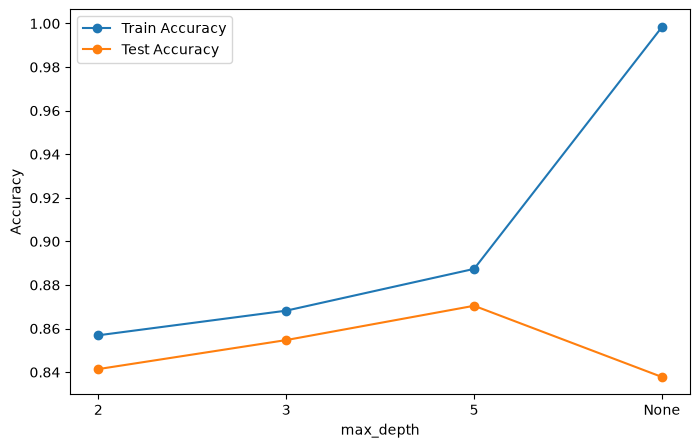

In [17]:
depth_rows = []

for depth in [2, 3, 5, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    depth_rows.append({
        "max_depth": str(depth),
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred),
        "test_recall": recall_score(y_test, test_pred, zero_division=0),
        "test_f1": f1_score(y_test, test_pred, zero_division=0),
        "nodes": model.tree_.node_count,
        "leaves": model.get_n_leaves(),
        "actual_depth": model.get_depth(),
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results)

plt.figure(figsize=(8, 5))
plt.plot(depth_results["max_depth"], depth_results["train_accuracy"], marker="o", label="Train Accuracy")
plt.plot(depth_results["max_depth"], depth_results["test_accuracy"], marker="o", label="Test Accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Mission 6 — Gini vs Entropy

Trong ví dụ Love AI, ta đã tính **Gini** và **Entropy / Information Gain** bằng tay.

Bây giờ hãy xem hai criterion này tạo ra cây như thế nào trên dữ liệu thật.
[TRẢ LỜI]

1. **Accuracy, Recall và F1 có khác nhau nhiều không?**
   - **Khác nhau rất ít (không đáng kể).**
   - Cụ thể:
     - **Accuracy:** Gini đạt `0.8553` vs Entropy đạt `0.8596` (Entropy nhỉnh hơn ~0.4%).
     - **Recall:** Gini đạt `0.6309` vs Entropy đạt `0.6474` (Entropy nhỉnh hơn ~1.6%).
     - **F1-score:** Gini đạt `0.6571` vs Entropy đạt `0.6695` (Entropy nhỉnh hơn ~1.2%).

2. **Root Node có giống nhau không?**
   - **Cùng đặc trưng (feature) nhưng khác ngưỡng (threshold):**
     - Cả hai mô hình đều chọn chung đặc trưng gốc là **`Attendance`**.
     - Tuy nhiên, ngưỡng cắt (threshold) có sự chênh lệch nhỏ: **`Attendance <= 70.5`** (đối với Gini) và **`Attendance <= 74.5`** (đối với Entropy).

3. **Ba split đầu tiên có giống nhau không?**
   - **Khác nhau về ngưỡng cắt và đặc trưng ở tầng tiếp theo:**
     - **Gini:** Tầng 1 cắt tại `Attendance <= 70.50`, tầng 2 kiểm tra `Hours_Studied <= 21.50` và `Hours_Studied <= 14.50`.
     - **Entropy:** Tầng 1 cắt tại `Attendance <= 74.50`, tầng 2 kiểm tra `Hours_Studied <= 19.50` và `Hours_Studied <= 16.50`.

4. **Hai cây có thể có hiệu năng gần giống nhau nhưng cấu trúc khác nhau không?**
   - **Có.** Trong thực tế, Gini Impurity và Entropy tuân theo hai công thức toán học khác nhau nhưng có biểu đồ hình parabol tương tự nhau. Do đó, chúng có thể tạo ra các điểm cắt (threshold) khác nhau và cấu trúc các nhánh con khác nhau, nhưng hiệu năng phân loại tổng thể (Accuracy, Precision, Recall, F1) gần như tương đương nhau.

In [7]:
criterion_rows = []
criterion_models = {}

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=4,
        random_state=42
    )
    model.fit(X_train, y_train)
    criterion_models[criterion] = model

    result, pred = evaluate_binary(
        f"Decision Tree ({criterion})",
        model,
        X_test,
        y_test,
        show_cm=False
    )

    root_idx = model.tree_.feature[0]
    result["root_feature"] = feature_cols[root_idx]
    result["root_threshold"] = model.tree_.threshold[0]
    result["depth"] = model.get_depth()
    result["nodes"] = model.tree_.node_count
    criterion_rows.append(result)

criterion_results = pd.DataFrame(criterion_rows)
display(criterion_results[
    ["model", "accuracy", "precision", "recall", "f1",
     "root_feature", "root_threshold", "depth", "nodes"]
])

for criterion, model in criterion_models.items():
    print("\n====", criterion.upper(), "====")
    print(export_text(model, feature_names=feature_cols, max_depth=2))

,model,accuracy,precision,recall,f1,root_feature,root_threshold,depth,nodes
0,Decision Tree (gini),0.855327,0.685629,0.630854,0.657102,Attendance,70.5,4,31
1,Decision Tree (entropy),0.859564,0.693215,0.647383,0.669516,Attendance,74.5,4,31



==== GINI ====
|--- Attendance <= 70.50
|   |--- Hours_Studied <= 21.50
|   |   |--- Hours_Studied <= 15.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- Hours_Studied >  15.50
|   |   |   |--- truncated branch of depth 2
|   |--- Hours_Studied >  21.50
|   |   |--- Hours_Studied <= 26.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- Hours_Studied >  26.50
|   |   |   |--- truncated branch of depth 2
|--- Attendance >  70.50
|   |--- Hours_Studied <= 14.50
|   |   |--- Attendance <= 80.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- Attendance >  80.50
|   |   |   |--- truncated branch of depth 2
|   |--- Hours_Studied >  14.50
|   |   |--- Attendance <= 78.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- Attendance >  78.50
|   |   |   |--- truncated branch of depth 2


==== ENTROPY ====
|--- Attendance <= 74.50
|   |--- Hours_Studied <= 19.50
|   |   |--- Attendance <= 65.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- At

# Mission 7 — Small GridSearch: tuning nhưng không biến thành black box

Dùng một không gian tham số nhỏ:

- `criterion`
- `max_depth`
- `min_samples_split`
- `min_samples_leaf`

Mục tiêu không phải “quét càng nhiều càng tốt”, mà quan sát cách hyperparameter kiểm soát độ phức tạp.

Ở đây dùng `scoring="f1"` để không chỉ tối ưu Accuracy.

[TRẢ LỜI]

1. **`best_params_` là gì?**
   - `best_params_` = `{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}`[cite: 13]

2. **Best tree sâu bao nhiêu?**
   - Độ sâu của Best tree (`Best tree depth`) là **5**[cite: 13].

3. **So với baseline, số node giảm hay tăng?**
   - **Số node giảm rất nhiều (giảm mạnh):**
     - Mô hình baseline có độ sâu không giới hạn (`max_depth=None`) tạo ra tới **1489 nodes**.
     - Trong khi đó, mô hình `GridSearch best` chỉ có **63 nodes**[cite: 13].

4. **Best CV score có giống Test F1 không? Vì sao không nên xem chúng là cùng một con số?**
   - **Không giống nhau:** `Best CV F1` = **0.681**[cite: 13], trong khi `Test F1` = **0.678679** (khoảng 0.679)[cite: 13].
   - **Lý do không nên xem chúng là cùng một con số:**
     - **Best CV score** (Cross-Validation Score) là trung bình điểm đánh giá qua các fold trên **tập huấn luyện (Training set)** nhằm hỗ trợ tìm kiếm và chọn ra bộ tham số tốt nhất[cite: 13].
     - **Test F1** là chỉ số thu được khi kiểm thử mô hình tối ưu đó trên **tập dữ liệu kiểm thử hoàn toàn mới (Test set)** mà mô hình chưa từng gặp[cite: 13]. Dữ liệu Test đại diện cho khả năng tổng quát hóa thực tế của mô hình.

Best params: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV F1: 0.681
Best tree depth: 5
Best tree nodes: 63
Best tree leaves: 32


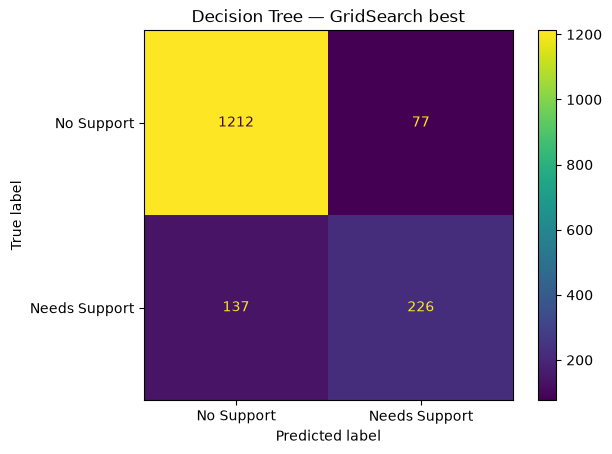

,model,accuracy,precision,recall,f1,fn,fp
0,Decision Tree baseline,0.837772,0.633803,0.619835,0.626741,138,130
1,Decision Tree — GridSearch best,0.870460,0.745875,0.622590,0.678679,137,77


In [8]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_tree = grid.best_estimator_

print("Best params:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 4))
print("Best tree depth:", best_tree.get_depth())
print("Best tree nodes:", best_tree.tree_.node_count)
print("Best tree leaves:", best_tree.get_n_leaves())

best_result, best_pred = evaluate_binary(
    "Decision Tree — GridSearch best",
    best_tree,
    X_test,
    y_test
)
display(pd.DataFrame([baseline_result, best_result])[
    ["model", "accuracy", "precision", "recall", "f1", "fn", "fp"]
])

# Mission 8 — Explain one student: vì sao mô hình dự đoán như vậy?

Chọn **một sinh viên trong test set** và dùng `decision_path()` để xem mẫu đó đi qua những node nào.

### Nhiệm vụ

Node 0: Attendance <= 70.50
-> đi phải (vì Attendance = 75.00 > 70.50)
Node 32: Hours_Studied <= 14.50
-> đi phải (vì Hours_Studied = 24.00 > 14.50)
Node 48: Attendance <= 78.50
-> đi trái (vì Attendance = 75.00 <= 78.50)
Node 49: Hours_Studied <= 18.50
-> đi phải (vì Hours_Studied = 24.00 > 18.50)
Node 53: Previous_Scores <= 71.50
-> đi phải (vì Previous_Scores = 94.00 > 71.50)
Leaf 55: Needs_Support = 0 (No Support)

**Giải thích:**
Sinh viên này có tỉ lệ đi học ở mức khá (75%), số giờ học cao (24 giờ) và điểm số trước đó rất tốt (94 điểm). Từng điều kiện rẽ nhánh đều xác nhận sinh viên đạt vượt mức tiêu chuẩn tối thiểu ở các môn học và điểm số, dẫn mô hình đến kết luận lá cuối cùng là sinh viên này không cần trợ giúp đặc biệt.

[TRẢ LỜI]

* **Prediction =** 0 (No Support)
* **Actual =** 0 (No Support)
* **Đường đi quan trọng nhất =** Node 0 (Attendance > 70.50) -> Node 32 (Hours_Studied > 14.50) -> Node 53 (Previous_Scores > 71.50).
* **Tôi có thấy prediction này hợp lý theo logic của cây không? Vì sao?**
  - **Có, hoàn toàn hợp lý.** 
  - **Vì:** Sinh viên có các chỉ số học tập đều rất tích cực: tham gia 75% số buổi học, dành tới 24 giờ tự học và có điểm quá trình/điểm thi trước đó đạt 94. Mô hình đưa ra dự đoán `0` (không cần hỗ trợ) trùng khớp hoàn toàn với thực tế (`Actual = 0`), phản ánh đúng logic thực tế là sinh viên học chăm và điểm cao thì không thuộc nhóm nguy cơ cần can thiệp học tập.

In [9]:
student = X_test.iloc[[0]]
actual = int(y_test.iloc[0])
prediction = int(best_tree.predict(student)[0])

display(student)
print("Actual:", actual)
print("Prediction:", prediction)

node_indicator = best_tree.decision_path(student)
leaf_id = best_tree.apply(student)[0]

node_index = node_indicator.indices[
    node_indicator.indptr[0]:node_indicator.indptr[1]
]

print("\nDecision path:")
for node_id in node_index:
    if node_id == leaf_id:
        values = best_tree.tree_.value[node_id][0]
        predicted_class = int(best_tree.classes_[np.argmax(values)])
        print(f"Leaf {node_id}: predicted class = {predicted_class}")
        continue

    feature_index = best_tree.tree_.feature[node_id]
    threshold = best_tree.tree_.threshold[node_id]
    feature_name = feature_cols[feature_index]
    feature_value = float(student.iloc[0, feature_index])

    direction = "<=" if feature_value <= threshold else ">"
    print(
        f"Node {node_id}: {feature_name}={feature_value:.2f} "
        f"{direction} {threshold:.2f}"
    )

,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
3214,24,75,94,7


Actual: 0
Prediction: 0

Decision path:
Node 0: Attendance=75.00 > 70.50
Node 32: Hours_Studied=24.00 > 14.50
Node 48: Attendance=75.00 <= 78.50
Node 49: Hours_Studied=24.00 > 18.50
Node 53: Previous_Scores=94.00 > 71.50
Leaf 55: predicted class = 0


# Mission 9 — Model Showdown: K-NN vs Naive Bayes vs Decision Tree

So sánh ba cách suy luận trên **cùng test set**:

| Model | Cách ra quyết định |
|---|---|
| K-NN | khoảng cách → hàng xóm → bỏ phiếu |
| GaussianNB | prior + likelihood → posterior |
| Decision Tree | câu hỏi → nhánh → leaf |

K-NN dùng `StandardScaler` như Lab 02.  
GaussianNB và Decision Tree dùng dữ liệu gốc.

[TRẢ LỜI]

1. **Nếu ưu tiên không bỏ sót sinh viên cần hỗ trợ, metric nào quan trọng?**
   - Metric quan trọng nhất là **Recall** (đặc biệt là Recall đối với lớp "Needs Support").
   - **Lý do:** Recall đo lường tỉ lệ phát hiện đúng các trường hợp thực sự cần hỗ trợ. Recall càng cao thì số lượng sinh viên cần hỗ trợ bị bỏ sót (False Negative - FN) càng ít.

2. **Model nào có Recall cao hơn trên test set này?**
   - **K-NN (k=5 scaled)** có Recall cao nhất với **0.6446** (64.46%), tương ứng với số ca bỏ sót ít nhất (**FN = 129**).
   - *So sánh:* Decision Tree đạt Recall `0.6226` (FN = 137), còn GaussianNB đạt Recall `0.5950` (FN = 147).

3. **Model nào dễ giải thích trực quan nhất?**
   - **Decision Tree (Cây quyết định)** là mô hình dễ giải thích trực quan nhất.
   - **Lý do:** Mô hình biểu diễn tri thức dưới dạng các quy tắc "Nếu - Thì" (If-Then rules) rõ ràng. Ta có thể vẽ ra sơ đồ cây hoặc dùng `decision_path()` để chỉ rõ chính xác vì sao một sinh viên lại được xếp vào nhóm cần hỗ trợ (dựa trên ngưỡng của các biến như Attendance, Hours_Studied, Previous_Scores).

4. **Một model Accuracy cao hơn một chút nhưng khó giải thích hơn có chắc phù hợp hơn cho Learning Analytics không? Giải thích.**
   - **Không chắc chắn (không hẳn phù hợp hơn).**
   - **Giải thích:**
     - Trong ứng dụng giáo dục (**Learning Analytics**), tính **Khả năng giải thích được (Explainability/Interpretability)** đóng vai trò quan trọng không kém gì độ chính xác.
     - Cố vấn học tập và giảng viên cần biết **lý do cụ thể** tại sao sinh viên lại nằm trong danh sách cảnh báo (ví dụ: do nghỉ học nhiều hay do điểm số quá trình yếu) để đưa ra biện pháp hỗ trợ/can thiệp phù hợp.
     - Một mô hình có Accuracy nhỉnh hơn một chút (như GaussianNB đạt 87.8% vs Decision Tree đạt 87.0%) nhưng mang tính chất "hộp đen" hơn hoặc khó đưa ra hành động khắc phục cụ thể sẽ ít mang lại giá trị thực tiễn bằng mô hình dễ giải thích như Decision Tree.

In [10]:
# K-NN reference — same pipeline as Lab 02
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean")
knn.fit(X_train_scaled, y_train)
knn_result, knn_pred = evaluate_binary(
    "K-NN k=5 scaled",
    knn,
    X_test_scaled,
    y_test,
    show_cm=False
)

# Gaussian Naive Bayes — same pipeline as Lab 03
gnb = GaussianNB()
gnb.fit(X_train, y_train)
nb_result, nb_pred = evaluate_binary(
    "GaussianNB",
    gnb,
    X_test,
    y_test,
    show_cm=False
)

# Best Decision Tree
dt_result, dt_pred = evaluate_binary(
    "Decision Tree",
    best_tree,
    X_test,
    y_test,
    show_cm=False
)

showdown = pd.DataFrame([knn_result, nb_result, dt_result])
display(showdown[
    ["model", "accuracy", "precision", "recall", "f1", "fn", "fp"]
])

,model,accuracy,precision,recall,f1,fn,fp
0,K-NN k=5 scaled,0.860775,0.698507,0.644628,0.670487,129,101
1,GaussianNB,0.878329,0.800000,0.595041,0.682464,147,54
2,Decision Tree,0.870460,0.745875,0.622590,0.678679,137,77


# Optional Challenge — Decision Tree Regression

Decision Tree không chỉ dùng cho classification.

Nếu muốn thử thêm, dùng California Housing với `DecisionTreeRegressor`.

> Mặc định `RUN_OPTIONAL=False` để GitHub Actions không phụ thuộc vào việc tải thêm dataset.

[TRẢ LỜI]

* **Khi target chuyển từ nhãn lớp sang giá trị liên tục, leaf node biểu diễn điều gì?**
  - Leaf node (nút lá) không còn biểu diễn nhãn phân loại (như 0 hay 1) mà biểu diễn **giá trị trung bình (mean)** của biến mục tiêu (target) tính trên tất cả các mẫu dữ liệu thuộc về nút lá đó.

* **Metric đánh giá regression có còn là Accuracy/Recall không?**
  - **Không.** Accuracy và Recall chỉ dùng cho các bài toán phân loại (Classification).
  - Đối với bài toán hồi quy (Regression), các metric đánh giá được sử dụng là:
    - **MAE (Mean Absolute Error):** Sai số tuyệt đối trung bình (~0.529)[cite: 19].
    - **MSE / RMSE (Root Mean Squared Error):** Căn bậc hai của sai số bình phương trung bình (~0.726)[cite: 19].
    - **R² score (Coefficient of Determination):** Hệ số xác định, đo lường mức độ giải thích biến thiên của mô hình (~0.602)[cite: 19].

In [19]:
RUN_OPTIONAL = True

if RUN_OPTIONAL:
    from sklearn.datasets import fetch_california_housing
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

    housing = fetch_california_housing(as_frame=True)
    X_h = housing.data
    y_h = housing.target

    Xh_train, Xh_test, yh_train, yh_test = train_test_split(
        X_h, y_h, test_size=0.25, random_state=42
    )

    reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    reg.fit(Xh_train, yh_train)
    pred_h = reg.predict(Xh_test)

    print("MAE:", mean_absolute_error(yh_test, pred_h))
    print("RMSE:", mean_squared_error(yh_test, pred_h) ** 0.5)
    print("R2:", r2_score(yh_test, pred_h))
else:
    print("Optional Challenge skipped. Set RUN_OPTIONAL=True to run it.")

MAE: 0.5294242360347529
RMSE: 0.725809885363338
R2: 0.6018796993971511


# Final — Model Reflection Card
1. Decision Tree ra quyết định như thế nào?
[VIẾT]
Decision Tree ra quyết định bằng cách rẽ nhánh dữ liệu dựa trên chuỗi câu hỏi quy tắc "Nếu - Thì" (If-Then) theo từng đặc trưng (feature) và ngưỡng (threshold), đi từ Root Node qua các Internal Node cho đến khi chạm tới Leaf Node chứa kết quả dự đoán.

2. Root Node có ý nghĩa gì?
[VIẾT]
Root Node (Nút gốc) là điểm bắt đầu của cây, đại diện cho đặc trưng có khả năng phân loại dữ liệu tốt nhất (mang lại Information Gain lớn nhất hoặc làm giảm Gini Impurity nhiều nhất).

3. Gini và Entropy được dùng để làm gì?
[VIẾT]
Gini và Entropy được dùng làm độ đo tính không thuần khiết (Impurity) của dữ liệu tại một nút, giúp thuật toán chọn ra đặc trưng và ngưỡng cắt tối ưu nhất để chia nhỏ tập dữ liệu.

4. Vì sao cây quá sâu có thể gây overfitting?
[VIẾT]
Cây quá sâu sẽ phân chia dữ liệu thành quá nhiều nhánh nhỏ lẻ, học thuộc lòng cả những điểm dữ liệu nhiễu (noise) và trường hợp cá biệt của tập Train, dẫn đến việc mô hình đạt độ chính xác gần như 100% trên tập Train nhưng hoạt động kém trên tập Test.

5. Trong case study Needs_Support, False Negative có ý nghĩa gì?
[VIẾT]
False Negative (FN) là trường hợp một sinh viên thực sự cần hỗ trợ (Needs_Support = 1) nhưng mô hình lại dự đoán nhầm là không cần (Needs_Support = 0), dẫn đến hậu quả nghiêm trọng là sinh viên bị bỏ sót và không nhận được sự trợ giúp kịp thời.

6. Decision Tree cho biết điều gì rõ hơn K-NN và Naive Bayes?
[VIẾT]
Decision Tree cho biết rõ luồng logic ra quyết định (đường đi qua các ngưỡng điều kiện cụ thể) và tầm quan trọng của từng đặc trưng (Feature Importance), thay vì chỉ đưa ra kết quả phân loại dựa trên khoảng cách (K-NN) hay xác suất tổng thể (Naive Bayes).

7. Performance và interpretability có thể đánh đổi với nhau như thế nào?
[VIẾT]
Mô hình càng phức tạp (hoặc sâu) có thể đạt hiệu năng (Performance/Accuracy) cao hơn một chút nhưng lại trở nên giống "hộp đen" và khó giải thích (Interpretability). Nông cây hơn giúp mô hình cực kỳ dễ hiểu và trực quan nhưng có thể chấp nhận giảm nhẹ một lượng nhỏ hiệu năng dự đoán.

8. Một câu chốt
| Love AI giúp tôi hiểu cơ chế của Decision Tree; Student Performance Factors giúp tôi thấy rằng...
[VIẾT]
Love AI giúp tôi hiểu cơ chế của Decision Tree; Student Performance Factors giúp tôi thấy rằng việc kiểm soát độ sâu cây (pruning/tuning) là chìa khóa để cân bằng giữa hiệu năng dự đoán và khả năng giải thích thực tiễn trong Learning Analytics.
## Trước khi push

```bash
python scripts/download_data.py
python tests/check_lab04.py
git add .
git commit -m "Complete Lab 04 Decision Tree"
git push
```

Sau khi push, kiểm tra tab **Actions** và đảm bảo workflow `Lab 04 Check` chạy thành công.